# Example 04: Soil curves and velocity profiles

The site models of pyGMM produce the inputs of a site response analysis: the modulus reduction and damping curves of a soil type, and a shear-wave velocity profile. This example compares the soil-curve models, with their dependence on confining stress, and two velocity-profile models.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import pygmm
from pygmm import velocity_profile

%matplotlib inline

## Modulus reduction and damping

Each soil-type class is constructed with the properties of the soil and `.curves()` returns the strains, modulus reduction and damping.

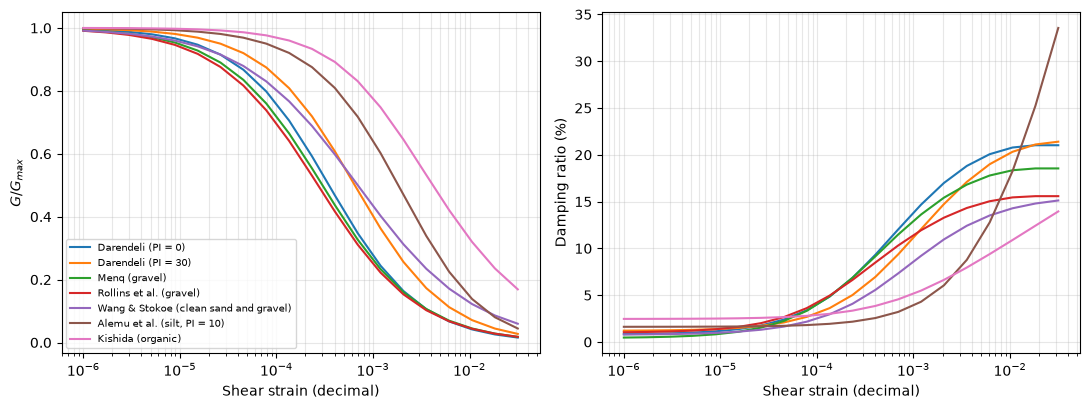

In [2]:
soils = {
    "Darendeli (PI = 0)": pygmm.DarendeliSoilType(
        unit_wt=18.0, plas_index=0, stress_mean=100.0
    ),
    "Darendeli (PI = 30)": pygmm.DarendeliSoilType(
        unit_wt=18.0, plas_index=30, stress_mean=100.0
    ),
    "Menq (gravel)": pygmm.MenqSoilType(unit_wt=20.0, stress_mean=100.0),
    "Rollins et al. (gravel)": pygmm.RollinsEtAlSoilType(
        unit_wt=20.0, stress_mean=100.0
    ),
    "Wang & Stokoe (clean sand and gravel)": pygmm.WangSoilType(
        "clean_sand_and_gravel", unit_wt=18.0, stress_mean=100.0
    ),
    "Alemu et al. (silt, PI = 10)": pygmm.AlemuEtAlSoilType(
        unit_wt=18.0, plas_index=10, stress_mean=100.0
    ),
    "Kishida (organic)": pygmm.KishidaSoilType(unit_wt=12.0, stress_vert=100.0),
}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharex=True)
for name, soil in soils.items():
    c = soil.curves()
    axes[0].plot(c.strains, c.mod_reduc, label=name)
    axes[1].plot(c.strains, 100 * c.damping, label=name)
axes[0].set(xscale="log", xlabel="Shear strain (decimal)", ylabel="$G / G_{max}$")
axes[1].set(xscale="log", xlabel="Shear strain (decimal)", ylabel="Damping ratio (%)")
for ax in axes:
    ax.grid(True, which="both", alpha=0.3)
axes[0].legend(fontsize=7)
fig.tight_layout()

## Dependence on confining stress

The Darendeli (2001) curves of a clay with a plasticity index of 30 at mean effective stresses of 25 to 800 kPa.

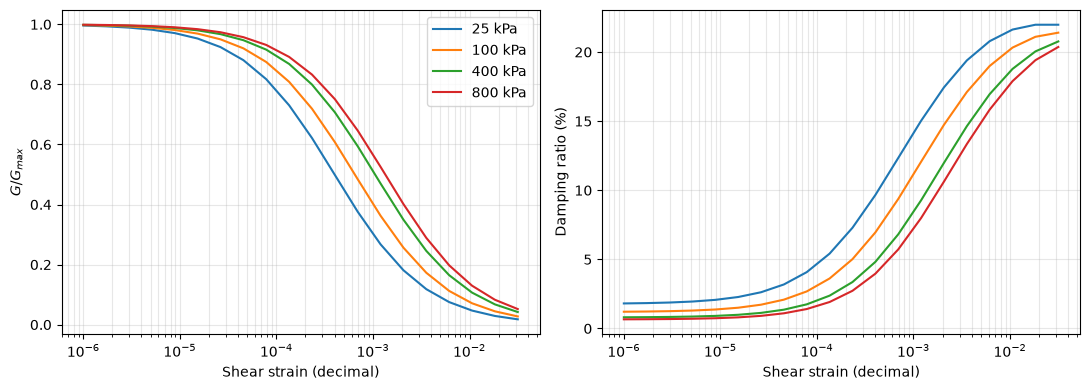

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True)
for stress in [25.0, 100.0, 400.0, 800.0]:
    c = pygmm.DarendeliSoilType(
        unit_wt=18.0, plas_index=30, stress_mean=stress
    ).curves()
    axes[0].plot(c.strains, c.mod_reduc, label=f"{stress:.0f} kPa")
    axes[1].plot(c.strains, 100 * c.damping, label=f"{stress:.0f} kPa")
axes[0].set(xscale="log", xlabel="Shear strain (decimal)", ylabel="$G / G_{max}$")
axes[1].set(xscale="log", xlabel="Shear strain (decimal)", ylabel="Damping ratio (%)")
for ax in axes:
    ax.grid(True, which="both", alpha=0.3)
axes[0].legend()
fig.tight_layout()

## Velocity profiles

Median profiles of Kamai et al. (2016, California) and Shi and Asimaki (2018) for three values of $V_{s30}$ (Kamai et al. is recommended for $V_{s30}$ of 250 to 850 m/s).

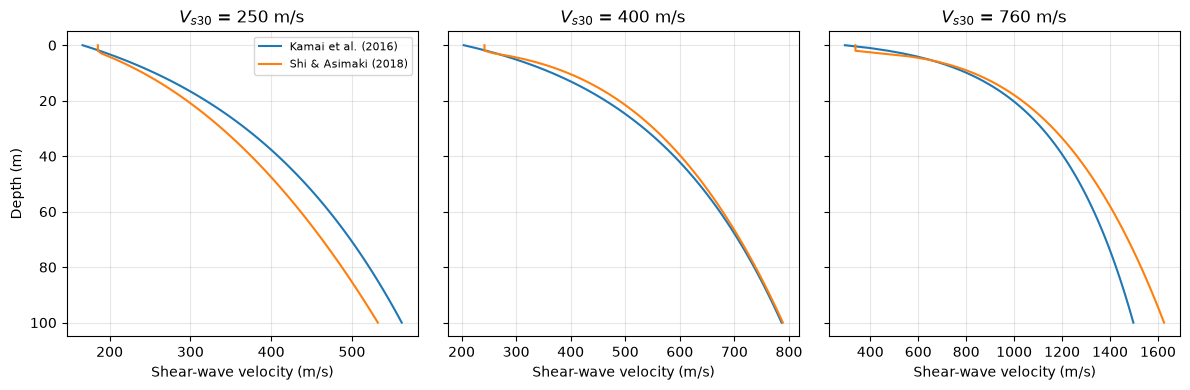

In [4]:
depth = np.linspace(0.0, 100.0, 101)

fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
for ax, v in zip(axes, [250.0, 400.0, 760.0]):
    profiles = {
        "Kamai et al. (2016)": velocity_profile.kea16_profile(depth, v, "california"),
        "Shi & Asimaki (2018)": velocity_profile.sa18_profile(depth, v),
    }
    for name, p in profiles.items():
        ax.plot(p.vs_median, p.depth, label=name)
    ax.set(xlabel="Shear-wave velocity (m/s)", title=f"$V_{{s30}}$ = {v:.0f} m/s")
    ax.grid(True, alpha=0.3)
axes[0].set_ylabel("Depth (m)")
axes[0].invert_yaxis()
axes[0].legend(fontsize=8)
fig.tight_layout()

### Observations

- **Plasticity increases the linearity**: at a strain of 0.1% the modulus reduction is 0.36 for a plasticity index of 30 and 0.24 for 0, at 100 kPa. The gravel models of Menq and of Rollins et al. are close to the non-plastic Darendeli curve, the organic soil of Kishida is the most linear, and the silt of Alemu et al. has the damping that increases fastest, to over 30% at 3% strain, while the others reach 14 to 21%.
- **Confining stress** also increases the linearity and reduces the damping: at 0.1% strain the modulus reduction is 0.27 at 25 kPa and 0.53 at 800 kPa and the damping 15% and 8%.
- **The two velocity profiles agree within about 10% for 400 m/s**, and differ for softer and stiffer sites: for 250 m/s Shi and Asimaki (2018) is lower at depth, and for 760 m/s it is higher (1620 m/s at 100 m against 1490 m/s).